In [12]:
from BlackScholes import monteCarloOptionPricing


S0 = 100  # Initial stock price
K = 100   # Strike price
T = 1     # Time to maturity (1 year)
r = 0.05  # Risk-free interest rate (5%)
sigma = 0.2  # Volatility (20%)
mu = 2*r

mc = monteCarloOptionPricing(S0, K, T, r, sigma, mu, num_simulations = 10000)
asset_prices, call_prices, put_prices = mc.monte_carlo_option_price()


The distribution of prices at expiration date $T$  will be given by log normal distribuiton. 
$p(S_T = s, T) = \frac{1}{s\sqrt{2\pi \sigma^2 T}}
\exp\!\left[-\frac{\left(\log(s/S_0)  - \left(\mu - \tfrac{1}{2}\sigma^2\right) T\right)^2}{2\sigma^2 T}\right]$

10.450433404882538 13.949860391667608


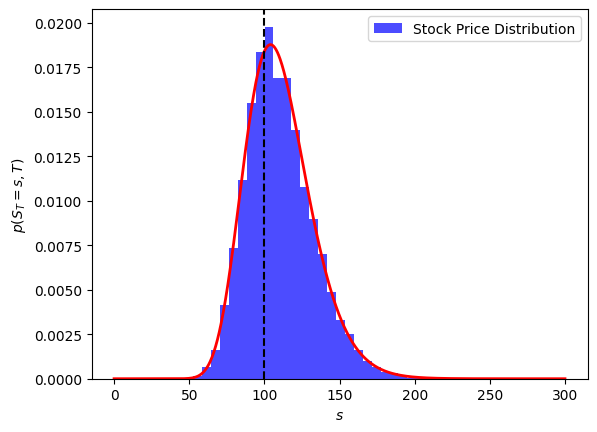

In [11]:
from scipy.stats import lognorm
from scipy.integrate import trapezoid
import numpy as np
import matplotlib.pyplot as plt

s = np.linspace(1e-6, 3*S0, 1000)
x0 = np.log(S0) + (r - 0.5 * sigma ** 2) * T
x1 = np.log(S0) + (mu - 0.5 * sigma ** 2) * T

pdf_risk_neutral = lognorm.pdf(s, s=sigma * np.sqrt(T), scale=np.exp(x0))
pdf_real = lognorm.pdf(s, s=sigma * np.sqrt(T), scale=np.exp(x1))

#The price of the option is given by
risk_neutral_discouted_payoff_avg = np.exp(-r * T) * trapezoid((s[s>=K]-K) * pdf_risk_neutral[s>=K],  s[s>=K]) #exp(-r * T) * EQ(max(S_t -K),0)
#The real discouted payoff expected is given by
real_discouted_payoff_avg = np.exp(-r * T) * trapezoid((s[s>=K]-K) * pdf_real[s>=K],  s[s>=K])

print(risk_neutral_discouted_payoff_avg, real_discouted_payoff_avg)

plt.plot(s, pdf_real, linewidth = 2, color='r')
plt.hist(asset_prices[:, -1], bins=30, alpha=0.7, color='blue', label='Stock Price Distribution', density=True)
plt.axvline(K, linestyle='--', color='k')
plt.ylabel(r'$p(S_T = s, T)$')
plt.xlabel(r'$s$')
plt.legend()




